# Inference Model: Logistic Regression for Statin Discontinuation

Survey-weighted logistic regression of statin discontinuation among adults in the MEPS longitudinal panel 27 (h252). The model uses the MEPS survey design fields (`LONGWT`, `VARSTR`, `VARPSU`), so the results represent U.S. adults who use statins.

In [1]:
# ---- Basic tools ----
import numpy as np
import pandas as pd

from pathlib import Path

# ---- Visualization ----
import matplotlib.pyplot as plt

# ---- Statistical inference ----
import statsmodels.api as sm
import warnings

## 1. Load the Dataset

The modeling dataset is derived from the previously prepared baseline person-level dataset.

Each observation represents one individual. The dataset contains the outcome variable, demographic characteristics, healthcare utilization, insurance information, and statin purchasing information.

One additional purchasing behavior feature is engineered during this stage:

single_fill: Binary indicator identifying individuals with exactly one statin purchase across Rounds 1 and 2.

The repository root is located dynamically to make the notebook easier to execute from different working directories.

In [2]:
# Find the project's main folder (the "repository root")
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "download_meps.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root."
    )

print(f"Repository: {ROOT}")

Repository: C:\Users\mfebu\Projects\statin-discontinuation


In [3]:
# Load the baseline dataset: one row per person, built by the scripts in src/
baseline = pd.read_csv(
    ROOT / "data" / "processed" / "baseline_person_dataset.csv",
    dtype={"DUPERSID": "string"}  # keep the person ID as text (keeps leading zeros)
)

# New field: 1 if the person bought a statin exactly once across rounds 1-2, else 0
baseline["single_fill"] = (
    (
        baseline["statin_purchase_count_round_1"]
        + baseline["statin_purchase_count_round_2"]
    ) == 1
).astype(int)

# Put the dataset in a dictionary so we can print its size
datasets = {
    "Final baseline dataset": baseline,
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

# Check there is exactly one row per person
assert baseline["DUPERSID"].is_unique
assert baseline["DUPERSID"].notna().all()

# Check the new field was created
assert "single_fill" in baseline.columns

print("\nOne row per person confirmed.")
print("Engineered features successfully created.")

display(
    baseline[
        [
            "statin_purchase_count_round_1",
            "statin_purchase_count_round_2",
            "single_fill"
        ]
    ].head(10)
)

Final baseline dataset: (1339, 80)

One row per person confirmed.
Engineered features successfully created.


,statin_purchase_count_round_1,statin_purchase_count_round_2,single_fill
0,0,2,0
1,1,10,0
2,0,11,0
3,0,1,1
4,1,2,0
5,0,1,1
6,0,2,0
7,1,0,1
8,0,3,0
9,1,1,0


## 2. Survey Design Fields

MEPS is a complex survey. To get correct p-values and confidence intervals we need three design fields:

- `LONGWT` – longitudinal person weight (already in the baseline dataset)
- `VARSTR` – variance strata
- `VARPSU` – variance primary sampling units (clusters)

`VARSTR` and `VARPSU` are not in the baseline dataset, so we read them from the longitudinal file `h252dta.zip` and join them on `DUPERSID`.

In [4]:
# Survey design fields: strata (VARSTR) and clusters (VARPSU) from the longitudinal file
import zipfile
import pyreadstat
import tempfile

zip_path = ROOT / "data" / "raw" / "h252dta.zip"
with zipfile.ZipFile(zip_path) as z:
    dta_name = [n for n in z.namelist()
                if n.lower().endswith(".dta")][0]
    dta_path = z.extract(dta_name, tempfile.mkdtemp())

design, _ = pyreadstat.read_dta(
    dta_path,
    usecols=["DUPERSID", "VARSTR", "VARPSU"]  # person ID, strata, cluster
)
design["DUPERSID"] = design["DUPERSID"].astype("string")

baseline = baseline.merge(design, on="DUPERSID",
                          how="left", validate="1:1")  # one row per person on both sides

assert baseline[["VARSTR", "VARPSU"]].notna().all().all()
print(baseline[["LONGWT_round_1", "VARSTR", "VARPSU"]].describe())

       LONGWT_round_1       VARSTR       VARPSU
count     1339.000000  1339.000000  1339.000000
mean     31439.261967  2056.803585     1.923077
std      23978.386807    34.787883     0.948241
min       1797.328530  2001.000000     1.000000
25%      17255.023905  2026.000000     1.000000
50%      26068.918915  2055.000000     2.000000
75%      38556.545571  2089.000000     2.000000
max     260973.883554  2117.000000     5.000000


## 3. Define the Outcome

The outcome is `discontinued`:

- 0 = kept buying statins
- 1 = no statin purchase in rounds 3-5 (potential discontinuation)

We check how many people are in each group before fitting the model.

In [5]:
# List every column name with a number
for i, col in enumerate(baseline.columns):
    print(f"{i+1:02d}. {col}")

# Show the first five people (without the person ID)
display(baseline.drop(columns="DUPERSID").head())

01. DUPERSID
02. discontinued
03. ALL5RDS_round_1
04. ALL5RDS_round_2
05. DIED_round_1
06. DIED_round_2
07. INST_round_1
08. INST_round_2
09. MILITARY_round_1
10. MILITARY_round_2
11. LEFTUS_round_1
12. LEFTUS_round_2
13. SEX_round_1
14. SEX_round_2
15. RACETHX_round_1
16. RACETHX_round_2
17. HISPANX_round_1
18. HISPANX_round_2
19. EDUCYR_round_1
20. EDUCYR_round_2
21. HIDEG_round_1
22. HIDEG_round_2
23. HWELLSPK_round_1
24. HWELLSPK_round_2
25. LONGWT_round_1
26. LONGWT_round_2
27. AGE_round_1
28. AGE_round_2
29. RTHLTH_round_1
30. RTHLTH_round_2
31. MNHLTH_round_1
32. MNHLTH_round_2
33. INS_round_1
34. INS_round_2
35. MCARE_round_1
36. MCARE_round_2
37. MCAID_round_1
38. MCAID_round_2
39. PRIVAT_round_1
40. PRIVAT_round_2
41. PMEDIN_round_1
42. PMEDIN_round_2
43. ELGRND_round_1
44. ELGRND_round_2
45. INSCOP_round_1
46. INSCOP_round_2
47. BEGRFM_round_1
48. BEGRFM_round_2
49. BEGRFY_round_1
50. BEGRFY_round_2
51. ENDRFM_round_1
52. ENDRFM_round_2
53. ENDRFY_round_1
54. ENDRFY_round_2


,discontinued,ALL5RDS_round_1,ALL5RDS_round_2,DIED_round_1,DIED_round_2,INST_round_1,INST_round_2,MILITARY_round_1,MILITARY_round_2,LEFTUS_round_1,...,new_condition_count_round_1,new_condition_count_round_2,active_icd10_codes_round_1,active_icd10_codes_round_2,active_ccsr_codes_round_1,active_ccsr_codes_round_2,statin_rx_cost_baseline_total,single_fill,VARPSU,VARSTR
0,0,1,1,0,0,0,0,0,0,0,...,2,0,C50; E03,C50; E03; E11; E78,END001; NEO030,END001; END002; END005; END010; NEO030,18.00,0,1,2113
1,0,1,1,0,0,0,0,0,0,0,...,1,0,E78,E78,END010,END010,110.00,0,3,2029
2,0,1,1,0,0,0,0,0,0,0,...,3,4,I10; M79; S82,E78; I10; M79; S82,CIR007; INJ042; MUS025,CIR007; END010; INJ000; INJ042; MUS025; RSP000...,72.46,0,3,2029
3,0,1,1,0,0,0,0,0,0,0,...,1,1,E11,E11; E78; M10,END002; END005,END002; END005; END010; MUS033,0.00,1,1,2031
4,0,1,1,0,0,0,0,0,0,0,...,3,2,E78; H40; Z96,E78; H40; M25; M48; Z96,END010; EYE003; FAC009,END010; EYE003; FAC009; MUS010; MUS011,47.21,0,3,2085


In [6]:
# Find columns whose name looks like an outcome
outcome_candidates = [
    col for col in baseline.columns
    if any(word in col.lower()
           for word in ["outcome", "discontinu", "label", "target", "continued"])
]

print(outcome_candidates)

['discontinued']


In [7]:
TARGET = "discontinued"  # the outcome: 1 = no statin purchase in rounds 3-5, 0 = kept buying

# How many people are 0 vs 1
print(baseline[TARGET].value_counts(dropna=False))

print("\nOutcome proportions:")
print(baseline[TARGET].value_counts(normalize=True))

# Check the outcome is clean
assert baseline[TARGET].notna().all()
assert set(baseline[TARGET].unique()).issubset({0, 1})

# Cohort size
print("\nTotal patients:", len(baseline))
print("Potential discontinuation:", (baseline[TARGET] == 1).sum())
print("Continued purchases:", (baseline[TARGET] == 0).sum())

discontinued
0    1232
1     107
Name: count, dtype: int64

Outcome proportions:
discontinued
0    0.92009
1    0.07991
Name: proportion, dtype: float64

Total patients: 1339
Potential discontinuation: 107
Continued purchases: 1232


The dataset contains 1,339 individuals, of whom 107 (8.0%) are classified
as potentially discontinuing statin purchases. The remaining 1,232
individuals (92.0%) continued purchasing.

## 4. Define the Explanatory Variables

The model includes two groups of variables:

- **Statin purchase behavior** (rounds 1-2): purchase counts, costs, and single fill.
- **Patient characteristics** (round 1): demographics, self-rated health, insurance, prescription use, and health conditions.

In [8]:
# All explanatory variables used in the model
TARGET = "discontinued"  # the outcome column

purchase_features = [
    "statin_purchase_count_round_1",
    "statin_purchase_count_round_2",
    "statin_rx_cost_round_1",
    "statin_rx_cost_round_2",
    "single_fill"
    # REMOVED: statin_rx_cost_baseline_total (= round 1 cost + round 2 cost, exact duplicate)
    # REMOVED: fill_change (= round 2 count - round 1 count, exact duplicate)
]

additional_features = [
    "AGE_round_1",
    "SEX_round_1",  # sex
    "RACETHX_round_1",  # race/ethnicity
    # REMOVED: HISPANX_round_1 (Hispanic is already code 1 of RACETHX, exact duplicate)
    "EDUCYR_round_1",  # years of education (used as a number)
    "HIDEG_round_1",  # highest degree
    "RTHLTH_round_1",  # physical health rating
    "MNHLTH_round_1",  # mental health rating
    "HWELLSPK_round_1",  # English speaking (not used in the model, see Section 5)
    "INS_round_1",  # any insurance
    "MCARE_round_1",  # Medicare
    "MCAID_round_1",  # Medicaid
    "PRIVAT_round_1",  # private insurance
    "PMEDIN_round_1",  # prescription coverage
    "rx_purchase_count_round_1",
    "rx_purchase_count_round_2",
    "distinct_drug_count_round_1",
    "distinct_drug_count_round_2",
    "active_condition_count_round_1",
    "active_condition_count_round_2",
]

full_features = purchase_features + additional_features

print("Purchase variables:", len(purchase_features))
print("Patient variables:", len(additional_features))
print("All variables:", len(full_features))

# Make sure every listed column really exists in the data
assert set(full_features).issubset(baseline.columns)

print("\nAll feature columns exist.")

Purchase variables: 5
Patient variables: 19
All variables: 24

All feature columns exist.


### What the codes mean

Code meanings come from the MEPS longitudinal file (h252). The **reference group** is the category every other category is compared against in the results.

| Variable | Codes | Reference group |
|---|---|---|
| `SEX` | 1 = Male, 2 = Female | Male |
| `RACETHX` | 1 = Hispanic, 2 = Non-Hispanic White, 3 = Non-Hispanic Black, 4 = Non-Hispanic Asian, 5 = Non-Hispanic Other/Multiple | Non-Hispanic White (largest group) |
| `HISPANX` | 1 = Hispanic, 2 = Not Hispanic. **Not used**: already code 1 of `RACETHX` | - |
| `EDUCYR` | Years of education: 0 = none, 12 = grade 12, 13-16 = 1-4 years of college, 17 = 5+ years of college | Used as a number: each extra year of school |
| `HIDEG` | 1 = No degree, 2 = GED, 3 = High school diploma, 4 = Bachelor's, 5 = Master's, 6 = Doctorate, 7 = Other degree | No degree |
| `RTHLTH` | Physical health: 1 = Excellent, 2 = Very good, 3 = Good, 4 = Fair, 5 = Poor | Excellent |
| `MNHLTH` | Mental health: 1 = Excellent, 2 = Very good, 3 = Good, 4 = Fair, 5 = Poor | Excellent |
| `INS` | Has any insurance: 1 = Yes, 2 = No | Yes |
| `MCARE` | Medicare: 1 = Yes, 2 = No | Yes |
| `MCAID` | Medicaid: 1 = Yes, 2 = No | Yes |
| `PRIVAT` | Private insurance: 1 = Yes, 2 = No | Yes |
| `PMEDIN` | Prescription drug coverage: 1 = Yes, 2 = No | Yes |

Codes -7 (refused) and -8 (don't know) are treated as missing (see Section 5).

## 5. Clean Special MEPS Values

MEPS uses special negative codes for answers that are not available (for example, -7 = refused, -8 = don't know).

These codes are not real values, so for education and self-rated health they are turned into missing values.

Missing values are filled in later, right before the model is fitted.

In [9]:
# Fields that are categories (codes), not real numbers
categorical_features = [
    "SEX_round_1",
    "RACETHX_round_1",
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "HWELLSPK_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1"
]

# Show how many people are in each category, for each field
for col in categorical_features:
    print(f"\n{col}")
    print(baseline[col].value_counts(dropna=False).sort_index())


SEX_round_1
SEX_round_1
1    657
2    682
Name: count, dtype: int64

RACETHX_round_1
RACETHX_round_1
1    193
2    896
3    170
4     50
5     30
Name: count, dtype: int64

EDUCYR_round_1
EDUCYR_round_1
-8       5
-7       1
 0       4
 1       4
 2       6
 3      11
 4      10
 5       5
 6      29
 7      12
 8      29
 9      33
 10     40
 11     41
 12    407
 13     96
 14    151
 15     32
 16    230
 17    193
Name: count, dtype: int64

HIDEG_round_1
HIDEG_round_1
-8      6
-7      1
 1    185
 2     74
 3    519
 4    239
 5    146
 6     35
 7    134
Name: count, dtype: int64

RTHLTH_round_1
RTHLTH_round_1
-7      1
 1    161
 2    432
 3    427
 4    228
 5     90
Name: count, dtype: int64

MNHLTH_round_1
MNHLTH_round_1
-7      1
 1    348
 2    414
 3    409
 4    143
 5     24
Name: count, dtype: int64

HWELLSPK_round_1
HWELLSPK_round_1
-1    1092
 1     105
 2      61
 3      43
 4      38
Name: count, dtype: int64

INS_round_1
INS_round_1
1    1292
2      47
Name: coun

Cleaning the special values

In [10]:
# Work on a copy so the original baseline table is not changed
model_data = baseline.copy()

# Fields where MEPS uses negative codes for "no answer"
missing_code_variables = [
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1"
]

# Turn those special codes into real missing values (NaN)
for col in missing_code_variables:
    model_data[col] = model_data[col].replace({
        -7: np.nan,  # -7 = refused -> missing
        -8: np.nan  # -8 = don't know -> missing
    })

# The English-speaking field is not used in the model
additional_features.remove("HWELLSPK_round_1")

# Rebuild the full list without that field
full_features = purchase_features + additional_features

print("Purchase variables:", len(purchase_features))
print("Patient variables:", len(additional_features))
print("All variables:", len(full_features))

print("\nMissing values after cleaning:")
display(
    model_data[full_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Purchase variables: 5
Patient variables: 18
All variables: 23

Missing values after cleaning:


HIDEG_round_1                     7
EDUCYR_round_1                    6
MNHLTH_round_1                    1
RTHLTH_round_1                    1
MCARE_round_1                     0
active_condition_count_round_1    0
distinct_drug_count_round_2       0
distinct_drug_count_round_1       0
rx_purchase_count_round_2         0
rx_purchase_count_round_1         0
dtype: int64

## 6. Identify Numerical and Categorical Variables

The explanatory variables are divided into two types:

- Numerical: age, years of education, purchase counts, prescription costs, and utilization counts. Missing values are filled with the median.
- Categorical: sex, race/ethnicity, highest degree, insurance, and self-rated health. Each one is turned into 0/1 columns, with the first category as the reference group.

In [11]:
# Final list of category fields (same as before, minus English speaking)
categorical_features = [
    "SEX_round_1",
    "RACETHX_round_1",
    # EDUCYR_round_1 is NOT here: it is a number of years, so it is used as a number.
    # As categories it had 18 small groups (some with 0 people who discontinued),
    # which kept the model from converging.
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1"
]

# Everything else in the full list is a number
numerical_features = [
    col for col in full_features
    if col not in categorical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['statin_purchase_count_round_1', 'statin_purchase_count_round_2', 'statin_rx_cost_round_1', 'statin_rx_cost_round_2', 'single_fill', 'AGE_round_1', 'EDUCYR_round_1', 'rx_purchase_count_round_1', 'rx_purchase_count_round_2', 'distinct_drug_count_round_1', 'distinct_drug_count_round_2', 'active_condition_count_round_1', 'active_condition_count_round_2']

Categorical features:
['SEX_round_1', 'RACETHX_round_1', 'HIDEG_round_1', 'RTHLTH_round_1', 'MNHLTH_round_1', 'INS_round_1', 'MCARE_round_1', 'MCAID_round_1', 'PRIVAT_round_1', 'PMEDIN_round_1']


## 7. Logistic Regression and Inference

This analysis estimates adjusted associations between patient characteristics and potential statin discontinuation.

It uses the full cohort (all 1,339 people) to estimate odds ratios, confidence intervals, and p-values.

Two versions are fitted:

- **unweighted_23:** every person counts the same.
- **weighted_23 (survey-weighted, final):** each person counts as the number of Americans they represent (`LONGWT`), and confidence intervals account for the survey design (`VARSTR`, `VARPSU`).

### Readable names for the results

The dictionary below turns codes into words, so the results show, for example, `Race: Non-Hispanic Black (vs Hispanic)` instead of `RACETHX_round_1_3`. It only changes the names; the model is the same.

In [12]:
# Readable names for each category variable: (short name, {code: meaning})
VALUE_LABELS = {
    "SEX_round_1":     ("Sex",               {1: "Male", 2: "Female"}),
    "RACETHX_round_1": ("Race",              {1: "Hispanic", 2: "Non-Hispanic White",
                                              3: "Non-Hispanic Black", 4: "Non-Hispanic Asian",
                                              5: "Non-Hispanic Other/Multiple"}),
    "HISPANX_round_1": ("Hispanic",          {1: "Yes", 2: "No"}),
    "EDUCYR_round_1":  ("Education",         {}),
    "HIDEG_round_1":   ("Highest degree",    {1: "No degree", 2: "GED", 3: "High school diploma",
                                              4: "Bachelor's", 5: "Master's", 6: "Doctorate",
                                              7: "Other degree"}),
    "RTHLTH_round_1":  ("Physical health",   {1: "Excellent", 2: "Very good", 3: "Good",
                                              4: "Fair", 5: "Poor"}),
    "MNHLTH_round_1":  ("Mental health",     {1: "Excellent", 2: "Very good", 3: "Good",
                                              4: "Fair", 5: "Poor"}),
    "INS_round_1":     ("Insured",           {1: "Yes", 2: "No"}),
    "MCARE_round_1":   ("Medicare",          {1: "Yes", 2: "No"}),
    "MCAID_round_1":   ("Medicaid",          {1: "Yes", 2: "No"}),
    "PRIVAT_round_1":  ("Private insurance", {1: "Yes", 2: "No"}),
    "PMEDIN_round_1":  ("Rx coverage",       {1: "Yes", 2: "No"}),
}

def code_to_words(col, code):
    short_name, meanings = VALUE_LABELS[col]
    if col == "EDUCYR_round_1":
        return f"{int(code)} years"
    return meanings.get(int(code), str(code))

In [13]:
# Build the table used for the inference model
inference_data = model_data[full_features].copy()

inference_data[TARGET] = model_data[TARGET].astype(int)

# Separate explanatory variables (X) and outcome (y)
X_inference = inference_data[full_features].copy()
y_inference = inference_data[TARGET]

# Fill in missing values so the model can run
for col in numerical_features:
    X_inference[col] = X_inference[col].fillna(
        X_inference[col].median()
    )

for col in categorical_features:
    X_inference[col] = X_inference[col].fillna(
        X_inference[col].mode()[0]
    )

# Tell pandas these fields are categories
for col in categorical_features:
    X_inference[col] = X_inference[col].astype("category")

# Race: make Non-Hispanic White (code 2), the largest group, the reference group (the first category is the reference)
race_levels = list(X_inference["RACETHX_round_1"].cat.categories)
white = next(level for level in race_levels if level == 2)
X_inference["RACETHX_round_1"] = X_inference["RACETHX_round_1"].cat.reorder_categories(
    [white] + [level for level in race_levels if level != 2]
)

# Turn each category field into 0/1 columns ("dummy variables")
X_inference_encoded = pd.get_dummies(
    X_inference,
    columns=categorical_features,
    drop_first=True,  # leave out the first level = the reference group
    dtype=float
)

# Make sure every column is a number
X_inference_encoded = X_inference_encoded.astype(float)

# Rename the 0/1 columns from codes to words, e.g. "RACETHX_round_1_3" -> "Race: Non-Hispanic Black (vs Non-Hispanic White)"
readable_names = {}
for col in categorical_features:
    levels = X_inference[col].cat.categories
    reference = levels[0]
    short_name = VALUE_LABELS[col][0]
    for level in levels[1:]:
        old_name = f"{col}_{level}"
        readable_names[old_name] = (
            f"{short_name}: {code_to_words(col, level)} "
            f"(vs {code_to_words(col, reference)})"
        )

assert set(readable_names).issubset(X_inference_encoded.columns)
X_inference_encoded = X_inference_encoded.rename(columns=readable_names)

# Add a column of 1s so the model has an intercept (baseline log-odds)
X_inference_encoded = sm.add_constant(
    X_inference_encoded,
    has_constant="add"
)

# Set up the logistic regression (statsmodels gives p-values and CIs)
# unweighted_23: every person counts the same (survey weights are added in weighted_23 below)
inference_model = sm.Logit(
    y_inference,
    X_inference_encoded
)

with warnings.catch_warnings():
    warnings.simplefilter("always")

    unweighted_23 = inference_model.fit(
        maxiter=200,  # try up to 200 steps to find the best coefficients
        disp=False
    )

print(unweighted_23.summary())

                           Logit Regression Results                           
Dep. Variable:           discontinued   No. Observations:                 1339
Model:                          Logit   Df Residuals:                     1301
Method:                           MLE   Df Model:                           37
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.1251
Time:                        21:29:19   Log-Likelihood:                -326.33
converged:                       True   LL-Null:                       -372.98
Covariance Type:            nonrobust   LLR p-value:                 9.222e-07
                                                                coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------
const                                                        -0.6226      1.335     -0.466      0.641      -3.239   

### weighted_23: Survey-weighted model (final)

MEPS does not sample people at random, so the plain model can give results that do not represent the U.S. population. weighted_23 fixes this:

- **`LONGWT` (weight):** each person counts as the number of Americans they represent. The weights are rescaled to average 1, so the total still equals 1,339 people.
- **`VARSTR` + `VARPSU` (strata and clusters):** people sampled from the same area tend to be alike. The confidence intervals are calculated by cluster, so they are wider and more honest.

This is a weighted logistic regression with cluster-robust standard errors, a common way to analyze MEPS in Python. (statsmodels may print a "SpecificationWarning" here; it is expected.)

In [14]:
# Survey weight: rescale LONGWT so the average weight is 1 (the total stays 1,339 people)
survey_weight = model_data["LONGWT_round_1"] / model_data["LONGWT_round_1"].mean()

# Cluster ID: one number for each (stratum, PSU) pair, e.g. stratum 2055 + PSU 2 -> 20552
cluster_id = (
    model_data["VARSTR"].astype(int) * 10
    + model_data["VARPSU"].astype(int)
)

# weighted_23: weighted logistic regression (GLM with a binomial family = logistic regression)
weighted_model = sm.GLM(
    y_inference,
    X_inference_encoded,
    family=sm.families.Binomial(),
    var_weights=survey_weight  # each person counts by their survey weight
)

weighted_23 = weighted_model.fit(
    cov_type="cluster",  # calculate confidence intervals by cluster...
    cov_kwds={"groups": cluster_id}  # ...using the stratum + PSU clusters
)

print("weighted_23 converged:", weighted_23.converged)
print("Number of clusters:", cluster_id.nunique())
print(weighted_23.summary())

weighted_23 converged: True
Number of clusters: 252
                 Generalized Linear Model Regression Results                  
Dep. Variable:           discontinued   No. Observations:                 1339
Model:                            GLM   Df Residuals:                     1301
Model Family:                Binomial   Df Model:                           37
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -316.62
Date:                Mon, 23 Nov 2026   Deviance:                       633.24
Time:                        21:29:19   Pearson chi2:                 1.58e+03
No. Iterations:                     7   Pseudo R-squ. (CS):            0.09162
Covariance Type:              cluster                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------

C:\Users\mfebu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Compare unweighted_23 and weighted_23

Side by side: odds ratio (OR) and p-value from each model. Only variables with p < 0.05 in at least one model are shown.

In [15]:
# Put both models' odds ratios and p-values in one table
comparison = pd.DataFrame({
    "OR (unweighted_23)": np.exp(unweighted_23.params),
    "p (unweighted_23)": unweighted_23.pvalues,
    "OR (weighted_23)": np.exp(weighted_23.params),
    "p (weighted_23)": weighted_23.pvalues,
}).drop("const")

significant_in_either = (comparison["p (unweighted_23)"] < 0.05) | (comparison["p (weighted_23)"] < 0.05)

display(comparison[significant_in_either].round(3))

,OR (unweighted_23),p (unweighted_23),OR (weighted_23),p (weighted_23)
single_fill,1.930,0.024,1.589,0.195
rx_purchase_count_round_2,1.033,0.031,1.062,0.001
distinct_drug_count_round_2,0.871,0.030,0.730,0.000
Race: Non-Hispanic Black (vs Non-Hispanic White),2.661,0.001,2.557,0.009
Race: Non-Hispanic Asian (vs Non-Hispanic White),1.951,0.185,3.167,0.014
Physical health: Fair (vs Excellent),0.379,0.041,0.585,0.364
Mental health: Good (vs Excellent),3.091,0.001,3.812,0.000
Mental health: Fair (vs Excellent),3.148,0.011,3.716,0.006
Mental health: Poor (vs Excellent),3.300,0.125,9.503,0.009
Insured: No (vs Yes),3.101,0.020,2.325,0.121


### Adjusted odds ratios and confidence intervals (weighted_23, final)

In [16]:
# The odds-ratio table below uses the FINAL model (weighted_23, survey-weighted)
final_results = weighted_23

# Coefficients = log-odds for each feature
coefficients = final_results.params

# 95% confidence intervals for each coefficient (in log-odds)
confidence_intervals = final_results.conf_int()

# Build a results table, turning log-odds into odds ratios with exp()
odds_ratio_results = pd.DataFrame({

    "Feature": coefficients.index,

    "Coefficient": coefficients.values,

    "Adjusted OR": np.exp(coefficients.values),  # odds ratio (>1 = higher odds of discontinuing)

    "CI Lower": np.exp(confidence_intervals[0].values),

    "CI Upper": np.exp(confidence_intervals[1].values),

    "P-value": final_results.pvalues.values  # chance of a result this strong if there were no real effect

})

# Remove the intercept row (it is not a patient feature)
odds_ratio_results = odds_ratio_results[
    odds_ratio_results["Feature"] != "const"
].copy()

# Flag features with p < 0.05
odds_ratio_results["Significant"] = (
    odds_ratio_results["P-value"] < 0.05
)

# Put the most significant features first
odds_ratio_results = odds_ratio_results.sort_values(
    "P-value"
).reset_index(drop=True)

display(
    odds_ratio_results.round(4)
)

,Feature,Coefficient,Adjusted OR,CI Lower,CI Upper,P-value,Significant
0,Mental health: Good (vs Excellent),1.3382,3.8120,1.9790,7.3427,0.0001,True
1,distinct_drug_count_round_2,-0.3151,0.7297,0.6135,0.8679,0.0004,True
2,rx_purchase_count_round_2,0.0601,1.0620,1.0260,1.0992,0.0006,True
3,Mental health: Fair (vs Excellent),1.3127,3.7164,1.4492,9.5307,0.0063,True
4,Mental health: Poor (vs Excellent),2.2516,9.5027,1.7619,51.2523,0.0088,True
5,Race: Non-Hispanic Black (vs Non-Hispanic White),0.9389,2.5572,1.2612,5.1851,0.0092,True
6,Race: Non-Hispanic Asian (vs Non-Hispanic White),1.1529,3.1673,1.2601,7.9615,0.0142,True
7,Highest degree: GED (vs No degree),-1.6321,0.1955,0.0347,1.1010,0.0642,False
8,rx_purchase_count_round_1,0.0474,1.0485,0.9968,1.1029,0.0663,False
9,Mental health: Very good (vs Excellent),0.5131,1.6704,0.8750,3.1890,0.1199,False


### Chart of adjusted odds ratios (weighted_23, final)

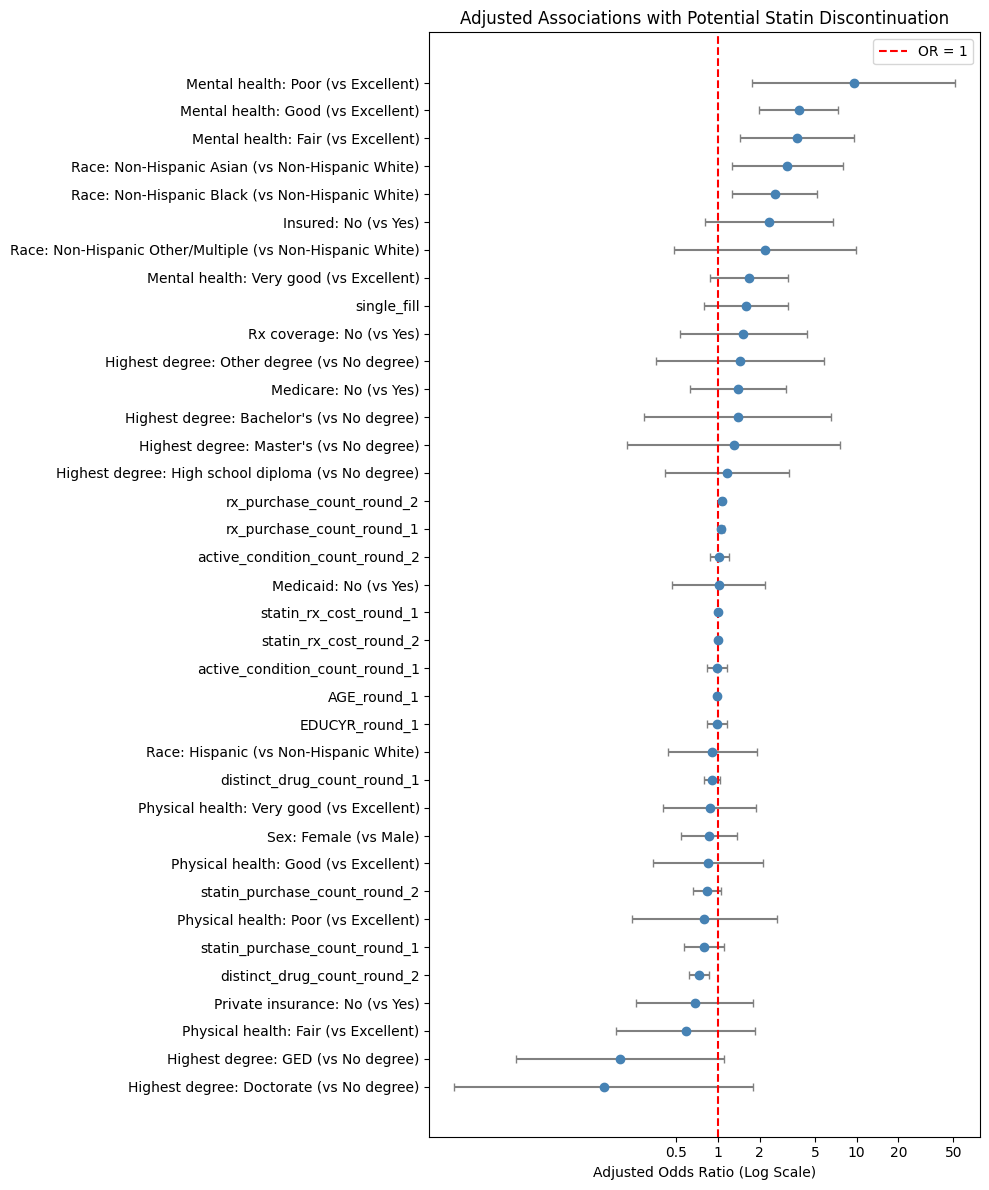

In [17]:
# Sort features by odds ratio for the chart (intercept already removed)
plot_data = odds_ratio_results.sort_values(
    "Adjusted OR"
).copy()

fig, ax = plt.subplots(figsize=(10, 12))

y_positions = np.arange(len(plot_data))

ax.errorbar(
    plot_data["Adjusted OR"],
    y_positions,
    xerr=[
        plot_data["Adjusted OR"] - plot_data["CI Lower"],
        plot_data["CI Upper"] - plot_data["Adjusted OR"]
    ],
    fmt="o",
    color="steelblue",
    ecolor="gray",
    capsize=3
)

ax.axvline(
    x=1,  # at OR = 1 (no association)
    color="red",
    linestyle="--",
    label="OR = 1"
)

ax.set_xscale("log")
ax.set_xticks(
    [0.5, 1, 2, 5, 10, 20, 50],
    labels=["0.5", "1", "2", "5", "10", "20", "50"]
)
ax.minorticks_off()

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Feature"])

ax.set_xlabel("Adjusted Odds Ratio (Log Scale)")
ax.set_title(
    "Adjusted Associations with Potential Statin Discontinuation"
)

ax.legend()
plt.tight_layout()
plt.show()

## 8. Save Summary Tables

Three summary tables for the RAG and the Streamlit app. They describe **subpopulations**, never individual patients, and contain no `DUPERSID`.

| File | What it holds |
|---|---|
| `inference_odds_ratios.csv` | Odds ratios, 95% CIs and p-values from weighted_23 |
| `subgroup_summary.csv` | Weighted % who stopped statins by group, with the weighted_23 odds ratio for each group |
| `subpopulation_drivers.csv` | Subpopulations linked to stopping (p < 0.05), mapped to RAG drivers |

Files are saved in `results/inference/`.

In [18]:
# Folder for the summary tables
OUTPUT_DIR = ROOT / "results" / "inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Readable labels for number variables, from the shared driver dictionary
driver_dictionary = pd.read_csv(ROOT / "results" / "driver_dictionary.csv")
number_labels = dict(zip(driver_dictionary["feature"], driver_dictionary["label"]))

print("Saving to:", OUTPUT_DIR)

Saving to: C:\Users\mfebu\Projects\statin-discontinuation\results\inference


### 8.1 Odds ratios (`inference_odds_ratios.csv`)

One row per variable in the model. Results from weighted_23 (the final model). The comparison with unweighted_23 is in Section 7.

In [19]:
# Which original variable each 0/1 column came from (e.g. "Race: Non-Hispanic Black (vs Non-Hispanic White)" -> RACETHX_round_1)
source_variable = {new: old.rsplit("_", 1)[0]
                   for old, new in readable_names.items()}

odds_ratio_table = pd.DataFrame({
    "variable": [source_variable.get(name, name)
                 for name in final_results.params.index],
    "label": [number_labels.get(name, name)
              for name in final_results.params.index],
    "odds_ratio_weighted": np.exp(final_results.params.values),
    "ci_lower_weighted": np.exp(final_results.conf_int()[0].values),
    "ci_upper_weighted": np.exp(final_results.conf_int()[1].values),
    "p_value_weighted": final_results.pvalues.values,
})

odds_ratio_table = odds_ratio_table[odds_ratio_table["variable"] != "const"]
odds_ratio_table["significant"] = odds_ratio_table["p_value_weighted"] < 0.05
odds_ratio_table = odds_ratio_table.sort_values("p_value_weighted").round(4)

odds_ratio_table.to_csv(OUTPUT_DIR / "inference_odds_ratios.csv", index=False)
display(odds_ratio_table.head(10))

,variable,label,odds_ratio_weighted,ci_lower_weighted,ci_upper_weighted,p_value_weighted,significant
30,MNHLTH_round_1,Mental health: Good (vs Excellent),3.8120,1.9790,7.3427,0.0001,True
11,distinct_drug_count_round_2,"Different medications, round 2",0.7297,0.6135,0.8679,0.0004,True
9,rx_purchase_count_round_2,"Prescription fills (all drugs), round 2",1.0620,1.0260,1.0992,0.0006,True
31,MNHLTH_round_1,Mental health: Fair (vs Excellent),3.7164,1.4492,9.5307,0.0063,True
32,MNHLTH_round_1,Mental health: Poor (vs Excellent),9.5027,1.7619,51.2523,0.0088,True
16,RACETHX_round_1,Race: Non-Hispanic Black (vs Non-Hispanic White),2.5572,1.2612,5.1851,0.0092,True
17,RACETHX_round_1,Race: Non-Hispanic Asian (vs Non-Hispanic White),3.1673,1.2601,7.9615,0.0142,True
19,HIDEG_round_1,Highest degree: GED (vs No degree),0.1955,0.0347,1.1010,0.0642,False
8,rx_purchase_count_round_1,"Prescription fills (all drugs), round 1",1.0485,0.9968,1.1029,0.0663,False
29,MNHLTH_round_1,Mental health: Very good (vs Excellent),1.6704,0.8750,3.1890,0.1199,False


### 8.2 Weighted % who stopped, by group (`subgroup_summary.csv`)

For each group: how many people are in the sample, how many people in the U.S. they represent (sum of `LONGWT`), and the **weighted** % who stopped statins. Groups with fewer than 30 people are flagged as unreliable. For groups that are categories in the model, the table also shows the **weighted_23** odds ratio, 95% CI and p-value ("reference" for the reference group). Age group and medication group are numbers in the model (one odds ratio per year or per drug), so they show the weighted % only.

In [20]:
# Helper columns for grouping
summary_data = model_data.copy()
summary_data["weight"] = summary_data["LONGWT_round_1"]
summary_data["age_group"] = pd.cut(
    summary_data["AGE_round_1"],
    bins=[0, 64, 74, 200],
    labels=["Under 65", "65-74", "75 and older"]
)
summary_data["drug_group"] = pd.cut(
    summary_data["distinct_drug_count_round_2"],
    bins=[-1, 2, 5, 8, 100],
    labels=["0-2 drugs", "3-5 drugs", "6-8 drugs", "9+ drugs"]
)

# Which groups to summarize: (subgroup name, column, {code: name} or None if already named)
subgroup_definitions = [
    ("Mental health", "MNHLTH_round_1", VALUE_LABELS["MNHLTH_round_1"][1]),
    ("Physical health", "RTHLTH_round_1", VALUE_LABELS["RTHLTH_round_1"][1]),
    ("Race", "RACETHX_round_1", VALUE_LABELS["RACETHX_round_1"][1]),
    ("Sex", "SEX_round_1", VALUE_LABELS["SEX_round_1"][1]),
    ("Insured", "INS_round_1", VALUE_LABELS["INS_round_1"][1]),
    ("Age group", "age_group", None),
    ("Different medications (round 2)", "drug_group", None),
]

rows = [{
    "subgroup": "All", "group": "All adults in the cohort",
    "n_sample": len(summary_data),
    "n_discontinued": int(summary_data[TARGET].sum()),
    "people_represented": summary_data["weight"].sum(),
    "pct_discontinued_weighted": 100 * (summary_data["weight"] * summary_data[TARGET]).sum() / summary_data["weight"].sum(),
}]

for subgroup_name, column, names in subgroup_definitions:
    for value, group in summary_data.dropna(subset=[column]).groupby(column, observed=True):
        rows.append({
            "subgroup": subgroup_name,
            "group": names.get(int(value), value) if names else str(value),
            "n_sample": len(group),
            "n_discontinued": int(group[TARGET].sum()),
            "people_represented": group["weight"].sum(),
            "pct_discontinued_weighted": 100 * (group["weight"] * group[TARGET]).sum() / group["weight"].sum(),
        })

subgroup_table = pd.DataFrame(rows)

# weighted_23 result for each group: odds ratio, 95% CI and p-value ("reference" for the reference group)
confidence_limits = final_results.conf_int()
column_of = {name: column for name, column, _ in subgroup_definitions}   # subgroup name -> model column

def model_result(subgroup_name, group_name):
    column = column_of.get(subgroup_name)
    if column not in categorical_features:                       # "All", age group, medication group
        return pd.Series({"odds_ratio_weighted": "", "ci_95_weighted": "", "p_value_weighted": ""})
    levels = list(X_inference[column].cat.categories)            # first level = reference group
    level = next(l for l in levels if code_to_words(column, l) == group_name)
    if level == levels[0]:
        return pd.Series({"odds_ratio_weighted": "reference", "ci_95_weighted": "reference", "p_value_weighted": "reference"})
    name = readable_names[f"{column}_{level}"]                   # the 0/1 column name in the model
    return pd.Series({
        "odds_ratio_weighted": round(float(np.exp(final_results.params[name])), 2),
        "ci_95_weighted": f"{np.exp(confidence_limits.loc[name, 0]):.2f}-{np.exp(confidence_limits.loc[name, 1]):.2f}",
        "p_value_weighted": round(float(final_results.pvalues[name]), 4),
    })

subgroup_table = pd.concat(
    [subgroup_table, subgroup_table.apply(lambda row: model_result(row["subgroup"], row["group"]), axis=1)],
    axis=1
)
subgroup_table["pct_of_population"] = 100 * subgroup_table["people_represented"] / summary_data["weight"].sum()
subgroup_table["reliable"] = subgroup_table["n_sample"] >= 30  # flag small groups (fewer than 30 people)
subgroup_table = subgroup_table.round(1)

subgroup_table.to_csv(OUTPUT_DIR / "subgroup_summary.csv", index=False)
display(subgroup_table)

,subgroup,group,n_sample,n_discontinued,people_represented,pct_discontinued_weighted,odds_ratio_weighted,ci_95_weighted,p_value_weighted,pct_of_population,reliable
0,All,All adults in the cohort,1339,107,42097171.8,8.2,,,,100.0,True
1,Mental health,Excellent,348,18,11319774.7,3.8,reference,reference,reference,26.9,True
2,Mental health,Very good,414,25,12907438.3,7.1,1.67,0.88-3.19,0.1199,30.7,True
3,Mental health,Good,409,47,12695456.0,12.2,3.81,1.98-7.34,0.0001,30.2,True
4,Mental health,Fair,143,14,4255511.2,9.1,3.72,1.45-9.53,0.0063,10.1,True
5,Mental health,Poor,24,3,877713.2,20.3,9.5,1.76-51.25,0.0088,2.1,False
6,Physical health,Excellent,161,13,5205840.3,6.1,reference,reference,reference,12.4,True
7,Physical health,Very good,432,29,13636384.7,6.8,0.87,0.40-1.88,0.7194,32.4,True
8,Physical health,Good,427,37,13496293.6,10.1,0.85,0.34-2.10,0.718,32.1,True
9,Physical health,Fair,228,18,6691160.0,7.6,0.59,0.18-1.86,0.3643,15.9,True


### 8.3 Subpopulations for the RAG (`subpopulation_drivers.csv`)

One row per subpopulation linked to stopping statins in weighted_23 (p < 0.05). Each row says which RAG driver it maps to (the driver names used in the RAG notebook and the question bank). The evidence text is built from the model results, so it updates when the model is rerun.

- **Actionable** subpopulations get outreach questions from the RAG.
- **Race** is reported as an equity finding: no outreach questions, because it is not something a patient can change. A race group is listed only if its p-value is below 0.05 (compared with Non-Hispanic White).
- The medication subpopulation uses 0-2 different medications in round 2.

In [21]:
# Helpers: odds ratio of one model column, as numbers and as text
def odds_ratio_of(name):
    return float(np.exp(final_results.params[name])), float(final_results.pvalues[name])

def category_column(column, code):                              # 0/1 column name for one category
    level = next(l for l in X_inference[column].cat.categories if l == code)
    return readable_names[f"{column}_{level}"]

mental_odds = [odds_ratio_of(category_column("MNHLTH_round_1", code))[0] for code in (3, 4, 5)]
drug_odds, _ = odds_ratio_of("distinct_drug_count_round_2")

# Each subpopulation: id, name, rule that selects its members, RAG driver, actionable?, evidence from weighted_23
subpopulation_definitions = [
    ("S01", "Adults rating their mental health good, fair, or poor",
     summary_data["MNHLTH_round_1"].isin([3, 4, 5]),
     "mental_health", True,
     "Mental health good / fair / poor vs excellent: OR " + " / ".join(f"{o:.1f}" for o in mental_odds)),
    ("S02", "Adults taking 0-2 different medications (round 2)",
     summary_data["distinct_drug_count_round_2"] <= 2,
     "med_count", True,
     f"Each extra different drug: OR {drug_odds:.2f} (fewer drugs = higher odds)"),
]

# Race groups: listed only if significant (p < 0.05) vs the reference group, as equity findings (no RAG driver)
race_levels = list(X_inference["RACETHX_round_1"].cat.categories)
race_reference = code_to_words("RACETHX_round_1", race_levels[0])
for level in race_levels[1:]:
    odds, p_value = odds_ratio_of(readable_names[f"RACETHX_round_1_{level}"])
    if p_value < 0.05:
        group = code_to_words("RACETHX_round_1", level)
        subpopulation_definitions.append((
            f"S{len(subpopulation_definitions) + 1:02d}", f"{group} adults",
            summary_data["RACETHX_round_1"] == level,
            "", False,                                          # no RAG driver: equity finding only
            f"{group} vs {race_reference}: OR {odds:.1f} (p = {p_value:.3f})",
        ))

def weighted_pct(rows):
    return 100 * (rows["weight"] * rows[TARGET]).sum() / rows["weight"].sum()

subpop_rows = []
for subpop_id, name, members, rag_driver, actionable, evidence in subpopulation_definitions:
    inside = summary_data[members]
    outside = summary_data[~members]
    subpop_rows.append({
        "subpop_id": subpop_id,
        "subpopulation": name,
        "rag_driver": rag_driver,
        "actionable": actionable,
        "evidence": evidence,
        "n_sample": len(inside),
        "people_represented": round(inside["weight"].sum()),
        "pct_discontinued_weighted": round(weighted_pct(inside), 1),
        "pct_discontinued_rest": round(weighted_pct(outside), 1),
    })

subpopulation_table = pd.DataFrame(subpop_rows)
subpopulation_table.to_csv(OUTPUT_DIR / "subpopulation_drivers.csv", index=False)
display(subpopulation_table)

,subpop_id,subpopulation,rag_driver,actionable,evidence,n_sample,people_represented,pct_discontinued_weighted,pct_discontinued_rest
0,S01,"Adults rating their mental health good, fair, ...",mental_health,True,Mental health good / fair / poor vs excellent:...,576,17828680,11.8,5.6
1,S02,Adults taking 0-2 different medications (round 2),med_count,True,Each extra different drug: OR 0.73 (fewer drug...,324,10921845,15.7,5.6
2,S03,Non-Hispanic Black adults,,False,Non-Hispanic Black vs Non-Hispanic White: OR 2...,170,3880920,14.3,7.6
3,S04,Non-Hispanic Asian adults,,False,Non-Hispanic Asian vs Non-Hispanic White: OR 3...,50,1960705,18.6,7.7


In [22]:
# Privacy check: no person IDs in any saved file
for csv_file in OUTPUT_DIR.glob("*.csv"):
    text = csv_file.read_text(encoding="utf-8")
    assert "DUPERSID" not in text, f"DUPERSID found in {csv_file.name}"
    print("OK, no DUPERSID:", csv_file.name)

OK, no DUPERSID: inference_odds_ratios.csv
OK, no DUPERSID: subgroup_summary.csv
OK, no DUPERSID: subpopulation_drivers.csv
